In [1]:
import recap
import pickle
import rdkit
from rdkit import Chem
import matplotlib.pyplot as plt
from rdkit.Chem import AllChem
import networkx as nx
import pandas as pd
import ipycytoscape
import time
from urllib import parse
from rdkit.Chem.Draw import IPythonConsole, MolsToGridImage
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem import rdChemReactions as Reactions
from IPython.display import display

In [3]:
# Load the Natural Products Library data

with open('../common-graph-delivery/data/BUL_ddd.pkl', 'rb') as f:
    BUL = pickle.load(f)

In [3]:
# Define the reactions. IMPORTANT: USE rdkit.Allchem.ReactionFromSmarts(). NEVER, EVER USE rdkit.Chem module for reactions

reactionsMol2 = {}
errors = 0
df = pd.read_csv('../envipath-api/All_EAWAG-rules.tsv', delimiter='\t')
for row in df.iterrows():
    idx = row[1]['Rule']
    smirks = row[1]['Smirks']
    try:
        rxn = AllChem.ReactionFromSmarts(smirks)
        reactionsMol2[idx] = rxn
    except Exception as e:
        errors +=1
        print (e)
        continue
        
reactionsMol2

ChemicalReactionParserException: Problems constructing reactant from SMARTS: [#7:7]\[#6:1](-[#7:8])=[#7]\?[#7+](-[#8-])=O


[12:06:39] SMARTS Parse Error: syntax error while parsing: [#7:7]\[#6:1](-[#7:8])=[#7]\?[#7+](-[#8-])=O
[12:06:39] SMARTS Parse Error: Failed parsing SMARTS '[#7:7]\[#6:1](-[#7:8])=[#7]\?[#7+](-[#8-])=O' for input: '[#7:7]\[#6:1](-[#7:8])=[#7]\?[#7+](-[#8-])=O'


{'bt0001-3568': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad46806e00>,
 'bt0002-3673': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad46806860>,
 'bt0003-1196': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad46807160>,
 'bt0005-3667': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad468073a0>,
 'bt0005-3776': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad46806f80>,
 'bt0005-4282': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad46807340>,
 'bt0011-4163': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad468071c0>,
 'bt0011-4163.2': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad468074c0>,
 'bt0012-4164': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad46806f20>,
 'bt0012-4164.2': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad46807280>,
 'bt0013-4165': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad468070a0>,
 'bt0013-4165.2': <rdkit.Chem.rdChemReactions.ChemicalReaction at 0x2ad46807220>,
 'bt0014-4215': <rdkit.Chem.rdChem

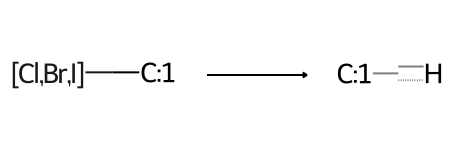

In [53]:
reactionsMol2['bt0029-3674']

In [87]:
df = pd.read_csv('data/PAH.csv')
df.head()

,cmpdname,cid,cas,iupacname,cmpdsynonym,mw,mf,polararea,complexity,xlogp,heavycnt,hbonddonor,hbondacc,rotbonds,inchi,isosmiles,inchikey,aids,Unnamed: 18
0,Naphthalene,931,91-20-3,naphthalene,"['naphthalene', '91-20-3', 'Naphthalin', 'Tar ...",128.17,C10H8,0.0,80.6,3.3,10,0,0,0,InChI=1S/C10H8/c1-2-6-10-8-4-3-7-9(10)5-1/h1-8H,C1=CC=C2C=CC=CC2=C1,UFWIBTONFRDIAS-UHFFFAOYSA-N,"[330, 421, 426, 427, 433, 434, 435, 445, 530, ...",
1,Phenanthrene,995,85-01-8,phenanthrene,"['PHENANTHRENE', '85-01-8', 'Phenanthren', 'Ph...",178.23,C14H10,0.0,174.0,4.5,14,0,0,0,InChI=1S/C14H10/c1-3-7-13-11(5-1)9-10-12-6-2-4...,C1=CC=C2C(=C1)C=CC3=CC=CC=C32,YNPNZTXNASCQKK-UHFFFAOYSA-N,"[248, 421, 426, 427, 433, 434, 435, 445, 530, ...",
2,4-Aminoantipyrine,2151,83-07-8,"4-amino-1,5-dimethyl-2-phenylpyrazol-3-one","['4-Aminoantipyrine', 'AMPYRONE', '83-07-8', '...",203.24,C11H13N3O,49.6,305.0,0.1,15,1,3,1,InChI=1S/C11H13N3O/c1-8-10(12)11(15)14(13(8)2)...,CC1=C(C(=O)N(N1C)C2=CC=CC=C2)N,RLFWWDJHLFCNIJ-UHFFFAOYSA-N,"[256, 357, 377, 410, 411, 422, 436, 444, 445, ...",
3,Benzo(a)pyrene,2336,50-32-8,benzo[a]pyrene,"['benzo[a]pyrene', '50-32-8', '3,4-Benzopyrene...",252.30,C20H12,0.0,372.0,6.0,20,0,0,0,InChI=1S/C20H12/c1-2-7-17-15(4-1)12-16-9-8-13-...,C1=CC=C2C3=C4C(=CC2=C1)C=CC5=C4C(=CC=C5)C=C3,FMMWHPNWAFZXNH-UHFFFAOYSA-N,"[1, 3, 5, 7, 9, 13, 15, 19, 21, 23, 25, 29, 31...",
4,"Dibenzo(a,h)anthracene",5889,53-70-3,"naphtho[1,2-b]phenanthrene","['Dibenz[a,h]anthracene', '53-70-3', 'benzo[k]...",278.30,C22H14,0.0,361.0,6.5,22,0,0,0,InChI=1S/C22H14/c1-3-7-19-15(5-1)9-11-17-14-22...,C1=CC=C2C(=C1)C=CC3=CC4=C(C=CC5=CC=CC=C54)C=C32,LHRCREOYAASXPZ-UHFFFAOYSA-N,"[155, 157, 161, 165, 167, 175, 180, 228, 234, ...",


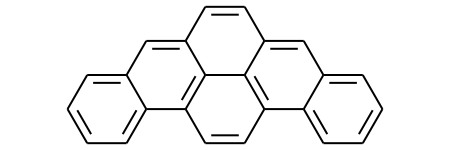

In [115]:
molecules = [Chem.MolFromSmiles(x) for x in df['isosmiles'].values]
molecules[10]

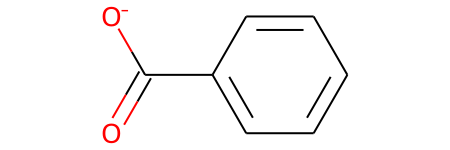

In [100]:
# The molecule (Benzoate)

mol = Chem.MolFromSmiles('C1=CC=C(C=C1)C(=O)[O-]')
mol

# Start Testing RECAP algorithm

In [116]:
# Initialize the recap algorithm. Include the molecule to analyse, the reactions and the NP library.
fragmentNet = recap.FragmentNet(molecules[4], reactionsMol2, BUL)

In [117]:
start_time = time.time()
fragmentNet.run_recap(core=molecules[0], keggAlign=False, useHs=True, verbose=True, forceNPLeaves=False, sanitizeFlag=False)
print("--- %s seconds ---" % (time.time() - start_time))

The Maximum number of nodes (100) was achieved
--- 3.1699368953704834 seconds ---


In [118]:
fragmentNet.graph.nodes

NodeView(('c1ccc2c(c1)ccc1cc3c(ccc4ccccc43)cc12', 'C1=c2ccc3cc4c(ccc5ccccc54)cc3c2=CCC1', 'C1=CCC2C(=C1)C=Cc1cc3c(ccc4ccccc43)cc12', 'C1=CCC2C=Cc3cc4c(ccc5ccccc54)cc3C2=C1', 'c1ccc2c(c1)CCc1cc3c(ccc4ccccc43)cc1-2', 'C1=CC2Cc3c(ccc4ccccc34)C=C2c2ccccc21', 'C1=CC2C=c3c(ccc4ccccc34)=CC2c2ccccc21', 'C1=Cc2ccccc2C2Cc3ccc4ccccc4c3C=C12', 'OC1C=c2ccc3cc4c(ccc5ccccc54)cc3c2=CC1', 'OC1C=c2c(ccc3cc4c(ccc5ccccc54)cc23)=CC1', 'C1=Cc2cc3c(ccc4ccccc43)cc2C2CCCC=C12', 'C1=CC2CCCC=C2c2cc3ccc4ccccc4c3cc21', 'C1=C2CCc3cc4c(ccc5ccccc54)cc3C2=CCC1', 'C1=CC2Cc3c(ccc4ccccc34)C=C2C2=CCCC=C12', 'C1=c2ccc3cc4c(cc3c2=CCC1)CCc1ccccc1-4', 'C1=CCC2C=Cc3cc4c5c(ccc4cc3C2=C1)=CCCC=5', 'C1=c2ccc3cc4c5c(ccc4cc3c2=CCC1)=CCCC=5', 'C1=CCC2C(=C1)C=Cc1cc3c4c(ccc3cc12)=CCCC=4', 'C1=CC2=Cc3c(ccc4ccccc34)CC2C2=CCCC=C12', 'OC12CC=CC=C1C=Cc1cc3c(ccc4ccccc43)cc12', 'OC1C=CC=C2C=Cc3cc4c(ccc5ccccc54)cc3C21', 'C1=CCC2c3cc4ccc5ccccc5c4cc3C=CC2C1', 'C1=CCC2C(=C1)CCc1cc3c(ccc4ccccc43)cc12', 'C1=CCC2C(=C1)C=CC1Cc3c(ccc4ccccc34)C=C12', '

# Plot the Results

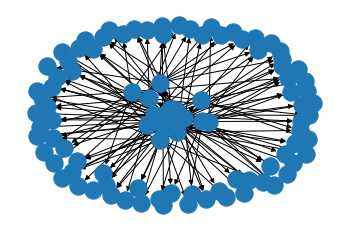

In [119]:
subax1 = plt.subplot()
nx.draw(fragmentNet.graph, with_labels=False, font_weight='bold')
plt.show()

In [120]:
directed = ipycytoscape.CytoscapeWidget()
directed.layout.height = '800px'
directed.layout.width = '970px'
directed.graph.add_graph_from_networkx(fragmentNet.graph, directed=True)

In [121]:
directed.set_layout(name='grid', nodeSpacing=200, edgeLengthVal=100)
directed.set_style([{'selector': "node[type = 'children']", 'css': {
                                'content': 'data(count)',
                                'text-valign': 'top',
                                'color': 'white',
                                'text-outline-width': 2,
                                'text-outline-color': '#FFFFFF',
                                'shape' : 'rectangle',
                                'width':100,
                                'height':100,
                                'border-width':5,
                                'border-color':'#24D5D5',
                                'curve-style':'straight',
                                'background-color': '#FFFFFF',
                                'background-fit':'contain',
                                'background-image':'data(img)'}},
                     
                        {'selector': "node[type = 'root']", 'css': {
                                'content': 'data(count)',
                                'text-valign': 'top',
                                'color': 'white',
                                'text-outline-width': 2,
                                'curve-style':'straight',
                                'text-outline-color': '#FFFFFF',
                                'shape' : 'rectangle',
                                'width':100,
                                'height':100,
                                'border-width':5,
                                'border-color':'#000000',
                                'background-color': '#FFFFFF',
                                'background-fit':'contain',
                                'background-image':'data(img)'}},
                    {'selector': "node[type = 'leave']", 'css': {
                                'content': 'data(count)',
                                'text-valign': 'top',
                                'color': 'white',
                                'text-outline-width': 2,
                                'curve-style':'straight',
                                'text-outline-color': '#FFFFFF',
                                'shape' : 'rectangle',
                                'width':100,
                                'height':100,
                                'border-width':5,
                                'border-color':'#eb4034',
                                'background-color': '#FFFFFF',
                                'background-fit':'contain',
                                'background-image':'data(img)'}},
                   {'selector':"edge.directed", 'css': {
                                "curve-style": "bezier",
                                'width': 4,
                                'label': 'data(reaction)',
                                'line-color': '#8334eb',
                                "target-arrow-shape": "triangle",
                                "target-arrow-color": '#8334eb'}},])
directed

CytoscapeWidget(cytoscape_layout={'name': 'grid', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style=[…